current time: t = 0.001
current time: t = 0.001999999999970011
current time: t = 0.002999896533959122
current time: t = 0.003999721849775895
current time: t = 0.0049995194998774875
current time: t = 0.005999315051367115
current time: t = 0.006999136426025244
current time: t = 0.007999006202015303
current time: t = 0.00899893165922823
current time: t = 0.009998878071022559
current time: t = 0.010998794166180346
current time: t = 0.01199872199699186
current time: t = 0.012998633184052508
current time: t = 0.013998546219095642
current time: t = 0.014998399591140488
current time: t = 0.015998217008902922
current time: t = 0.016998058993511686
current time: t = 0.01799795109660773
current time: t = 0.018997865745926004
current time: t = 0.019997750468402048
current time: t = 0.020997662223077022
current time: t = 0.021997541014511714
current time: t = 0.02299743781318081
current time: t = 0.023997269918251865
current time: t = 0.024997100973636367
current time: t = 0.02599697106185927
curre

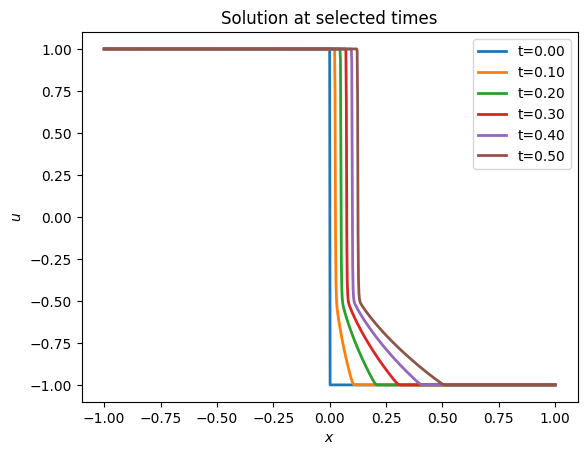

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

def u0(x):
    return np.where(x <= 0, 1, -1)

def f(u):
    return u ** 3 / 3

def WENO(a, u, dx):
    nx = len(u)
    n_stencil = 3
    I = np.arange(n_stencil-1, nx - n_stencil)

    # Compute the values at the right-hand sides of the cell boundaries (u_{i+1/2}^-) for candidate stencils
    vmm = u[I - 2]
    vm = u[I - 1]
    v = u[I]
    vp = u[I + 1]
    vpp = u[I + 2]

    p0n = (2 * vmm - 7 * vm + 11 * v) / 6
    p1n = (-vm + 5 * v + 2 * vp) / 6
    p2n = (2 * v + 5 * vp - vpp) / 6

    # Compute the weights for candidate stencils
    B0n = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1n = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2n = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0n = 1 / 10
    d1n = 6 / 10
    d2n = 3 / 10
    epsilon = 1e-6

    alpha0n = d0n / (epsilon + np.minimum(B0n, 1e30)) ** 2
    alpha1n = d1n / (epsilon + np.minimum(B1n, 1e30)) ** 2
    alpha2n = d2n / (epsilon + np.minimum(B2n, 1e30)) ** 2
    alphasumn = alpha0n + alpha1n + alpha2n

    # ENO stencils weigths
    w0n = alpha0n / alphasumn
    w1n = alpha1n / alphasumn
    w2n = alpha2n / alphasumn

    # Numerical Flux at cell boundary (u_{i+1/2}^{-})
    hn = w0n * p0n + w1n * p1n + w2n * p2n

    # Compute the values at the right-hand side of the cell boundaries (u_{i+1/2}^+)
    vmm = u[I - 1]
    vm = u[I]
    v = u[I + 1]
    vp = u[I + 2]
    vpp = u[I + 3]

    p0p = (-vmm + 5 * vm + 2 * v) / 6
    p1p = (2 * vm + 5 * v - vp) / 6
    p2p = (11 * v - 7 * vp + 2 * vpp) / 6

    B0p = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1p = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2p = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0p = 3 / 10
    d1p = 6 / 10
    d2p = 1 / 10
    epsilon = 1e-6

    alpha0p = d0p / (epsilon + np.minimum(B0p, 1e30)) ** 2
    alpha1p = d1p / (epsilon + np.minimum(B1p, 1e30)) ** 2
    alpha2p = d2p / (epsilon + np.minimum(B2p, 1e30)) ** 2
    alphasump = alpha0p + alpha1p + alpha2p

    # ENO stencils weigths
    w0p = alpha0p / alphasump
    w1p = alpha1p / alphasump
    w2p = alpha2p / alphasump

    # Numerical Flux at cell boundary (u_{i+1/2}^{+})
    hp = w0p * p0p + w1p * p1p + w2p * p2p

    LF = np.zeros_like(u)
    res = np.zeros_like(u)

    LF[I] = 0.5 * (f(hn) + f(hp) - abs(a) * (hp - hn)) # Lax-friedrichs flux

    res[I] = (LF[I] - LF[I - 1]) / dx     # L = -df(u) / dx

    return res

if __name__ == "__main__":
    T = 0.5
    CFL = 0.5
    N = 1000
    xl = -1
    xr = 1
    dx = (xr - xl) / N
    nx = N + 1
    x = np.linspace(xl, xr, nx)
    xg = np.concatenate((np.array([xl - 2 * dx, xl - dx]), x, np.array([xr + dx, xr + 2 * dx])))
    nxg = len(xg)

    ut0 = u0(xg)
    lambda0 = np.max(ut0**2)
    dt0 = CFL * dx / lambda0
    lbd = lambda0
    dt = dt0
    u = ut0
    t = 0

    res = [ut0.copy()]
    times = [0.0]
    iter = 0
    while t < T:
        if t + dt > T: dt = T - t
        t = t + dt

        uo = u
        L = WENO(lbd, u, dx)
        u = uo - dt * L

        # Enforce Dirichlet BC: set boundary points
        u[2] = 1.0
        u[nxg - 3] = -1.0
        # Set ghost cells (constant extension)
        u[0] = 1.0
        u[1] = 1.0
        u[-1] = -1.0
        u[-2] = -1.0

        L = WENO(lbd, u, dx)
        u = 0.75 * uo + 0.25 * (u - dt * L)

        # Enforce again
        u[2] = 1.0
        u[nxg - 3] = -1.0
        u[0] = 1.0
        u[1] = 1.0
        u[-1] = -1.0
        u[-2] = -1.0

        L = WENO(lbd, u, dx)
        u = (uo + 2 * (u - dt * L)) / 3

        # Enforce again
        u[2] = 1.0
        u[nxg - 3] = -1.0
        u[0] = 1.0
        u[1] = 1.0
        u[-1] = -1.0
        u[-2] = -1.0

        lbd = np.max(u**2)
        dt = CFL * dx / lbd

        res.append(u.copy())
        times.append(t)
        iter = iter + 1

        print("current time: t = {}".format(t))


    res = np.stack(res)

    # Save the solutions (all time steps, excluding ghosts) to a file
    np.savez('cubic_flux_ref.npz', times=times, x=x, u=res[:, 2:nxg-2])

    # Plot at t=0, 0.25, 0.5 (using closest available time steps)
    fig, ax = plt.subplots()
    desired_times = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
    times_array = np.array(times)
    for des in desired_times:
        i = np.argmin(np.abs(times_array - des))
        ax.plot(x, res[i, 2:nxg-2], label=f't={times[i]:.2f}', linewidth=2)
    ax.legend()
    plt.xlabel(r'$x$')
    plt.ylabel(r'$u$')
    plt.title('Solution at selected times')
    plt.savefig('cubic_flux_plot.png')
    plt.show()